# Discount Impact on Order Profitability

**Business question:** Does the discount rate applied to an order affect the profit earned on that order?

**Dataset:** Sample Superstore (U.S. retail order-level data, 2015-2018), mirrored from
`https://raw.githubusercontent.com/leonism/sample-superstore/master/data/superstore.csv`.
Originally distributed as Tableau's built-in sample dataset; widely used for teaching.

**H0:** rho = 0 -- no relationship between Discount and Profit
**H1:** rho != 0 -- a relationship exists (two-tailed)

| Variable | Role | Type |
|---|---|---|
| Discount | predictor | continuous, ratio (proportion, 0-0.8) |
| Profit | outcome | continuous, ratio (can be negative) |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
})
%matplotlib inline

## Load and clean the data

In [2]:
df = pd.read_csv("data/superstore.csv", encoding="latin1")
print(f"Raw shape: {df.shape}")

# 806 rows are entirely null across every column -- this is a structural
# artifact of this CSV mirror, not genuine missing data. We confirm this by
# checking the cleaned row count matches the dataset's well-known canonical
# size (9,994 rows) before trusting anything else about "missingness".
df = df.dropna(subset=["Order Date"]).copy()
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

print(f"Cleaned shape: {df.shape}")
print(f"Date range: {df['Order Date'].min().date()} to {df['Order Date'].max().date()}")

missing = df.isnull().sum()
print("\nGenuine missing values:")
print(missing[missing > 0])

Raw shape: (10800, 21)
Cleaned shape: (9994, 21)
Date range: 2015-01-03 to 2018-12-30

Genuine missing values:
Postal Code    11
dtype: int64


**Note on data quality:** the raw file had 10,800 rows; 806 of them were fully blank
(every column null), which is a quirk of this particular GitHub mirror rather than real
missingness in the underlying business data. After dropping those, we're left with 9,994
rows -- the well-known canonical size for this dataset, which is a useful sanity check that
the cleaning was done correctly rather than accidentally dropping real records. The only
genuine missing values are 11 `Postal Code` entries (0.1%), which don't matter for this
analysis and are left as-is.

## Descriptive Statistics -- every numeric column

In [3]:
numeric_cols = ["Sales", "Quantity", "Discount", "Profit"]
rows = []
for c in numeric_cols:
    s = df[c]
    q1, q3 = s.quantile([0.25, 0.75])
    rows.append({
        "column": c, "mean": s.mean(), "median": s.median(), "std": s.std(),
        "IQR": q3 - q1, "min": s.min(), "max": s.max(), "skew": s.skew(),
    })
desc = pd.DataFrame(rows).set_index("column").round(3)
desc

,mean,median,std,IQR,min,max,skew
column,,,,,,,
Sales,229.858,54.490,623.245,192.660,0.444,22638.480,12.973
Quantity,3.790,3.000,2.225,3.000,1.000,14.000,1.279
Discount,0.156,0.200,0.206,0.200,0.000,0.800,1.684
Profit,28.657,8.666,234.260,27.635,-6599.978,8399.976,7.561


In [4]:
categorical_cols = ["Segment", "Region", "Category", "Ship Mode"]
for c in categorical_cols:
    print(f"\n{c} (n={df[c].nunique()} unique):")
    print(df[c].value_counts().to_string())


Segment (n=3 unique):
Segment
Consumer       5191
Corporate      3020
Home Office    1783

Region (n=4 unique):
Region
West       3203
East       2848
Central    2323
South      1620

Category (n=3 unique):
Category
Office Supplies    6026
Furniture          2121
Technology         1847

Ship Mode (n=4 unique):
Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543


## Visualisations

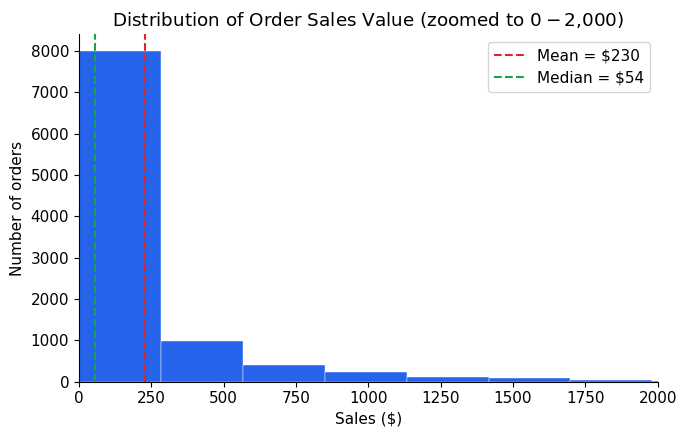

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(df["Sales"], bins=80, color="#2563eb", edgecolor="white", linewidth=0.3)
ax.set_xlim(0, 2000)
ax.set_title("Distribution of Order Sales Value (zoomed to $0-$2,000)")
ax.set_xlabel("Sales ($)"); ax.set_ylabel("Number of orders")
ax.axvline(df["Sales"].mean(), color="#dc2626", linestyle="--", label=f"Mean = ${df['Sales'].mean():.0f}")
ax.axvline(df["Sales"].median(), color="#16a34a", linestyle="--", label=f"Median = ${df['Sales'].median():.0f}")
ax.legend()
plt.tight_layout()
plt.show()

Sales is heavily right-skewed: most orders are small (median \$54), pulled up by a long tail of large orders (mean \$230). This flags Sales as a candidate for a log transform if it were going into a linear model -- see the distribution analysis of Profit below for the equivalent discussion.

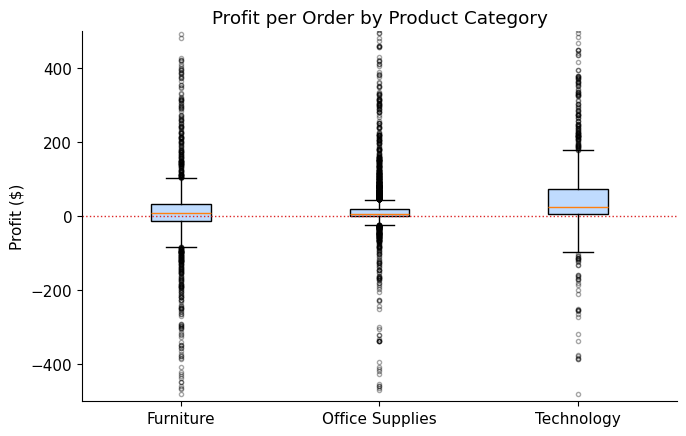

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
cats = df["Category"].unique()
data = [df.loc[df["Category"] == c, "Profit"] for c in cats]
bp = ax.boxplot(data, tick_labels=cats, patch_artist=True,
                 flierprops=dict(marker="o", markersize=3, alpha=0.35, color="#94a3b8"))
for patch in bp["boxes"]:
    patch.set_facecolor("#bfdbfe")
ax.axhline(0, color="#dc2626", linewidth=1, linestyle=":")
ax.set_ylim(-500, 500)
ax.set_title("Profit per Order by Product Category")
ax.set_ylabel("Profit ($)")
plt.tight_layout()
plt.show()

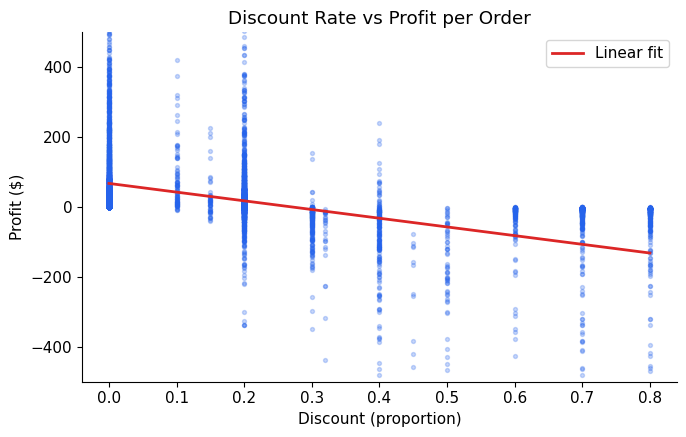

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["Discount"], df["Profit"], s=8, alpha=0.25, color="#2563eb")
z = np.polyfit(df["Discount"], df["Profit"], 1)
xline = np.linspace(0, df["Discount"].max(), 100)
ax.plot(xline, np.polyval(z, xline), color="#dc2626", linewidth=2, label="Linear fit")
ax.set_ylim(-500, 500)
ax.set_title("Discount Rate vs Profit per Order")
ax.set_xlabel("Discount (proportion)"); ax.set_ylabel("Profit ($)")
ax.legend()
plt.tight_layout()
plt.show()

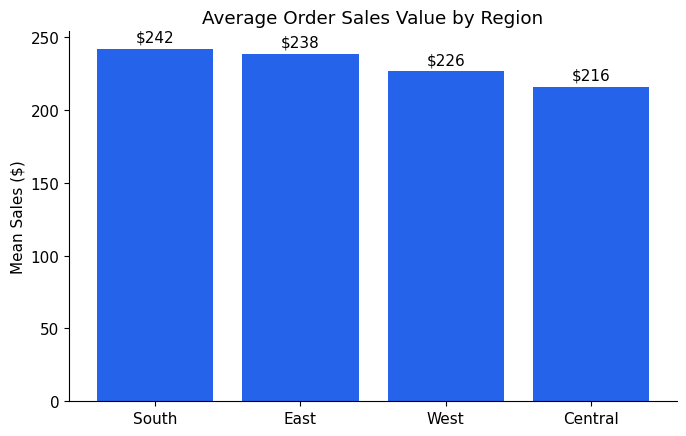

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
region_avg = df.groupby("Region")["Sales"].mean().sort_values(ascending=False)
bars = ax.bar(region_avg.index, region_avg.values, color="#2563eb")
ax.bar_label(bars, fmt="$%.0f", padding=3)
ax.set_title("Average Order Sales Value by Region")
ax.set_ylabel("Mean Sales ($)")
plt.tight_layout()
plt.show()

## Outlier check -- IQR rule

In [9]:
for col in ["Sales", "Profit", "Discount"]:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col}: bounds=[{lo:.2f}, {hi:.2f}]  outliers={n_out} ({n_out/len(df)*100:.1f}%)")

Sales: bounds=[-271.71, 498.93]  outliers=1167 (11.7%)
Profit: bounds=[-39.72, 70.82]  outliers=1881 (18.8%)
Discount: bounds=[-0.30, 0.50]  outliers=856 (8.6%)


**Decision: keep the outliers.** They're not data-entry errors -- they're large orders and
real losses, and since our business question is specifically about losses driven by
discounting, the "outliers" in Profit are exactly the observations that answer the
question. Removing them to satisfy the IQR rule would remove the signal we're trying to
measure.

## Hypothesis test

In [10]:
r, p_pearson = stats.pearsonr(df["Discount"], df["Profit"])
rho, p_spearman = stats.spearmanr(df["Discount"], df["Profit"])

print(f"n = {len(df)}")
print(f"Pearson  r   = {r:.4f}, p = {p_pearson:.2e}")
print(f"Spearman rho = {rho:.4f}, p = {p_spearman:.2e}")
print(f"R-squared = {r**2:.4f}  ->  Discount alone explains {r**2*100:.1f}% of the variance in Profit")

n = 9994
Pearson  r   = -0.2195, p = 2.70e-109
Spearman rho = -0.5434, p = 0.00e+00
R-squared = 0.0482  ->  Discount alone explains 4.8% of the variance in Profit


Pearson (r = -0.22) and Spearman (rho = -0.54) disagree by a lot. Pearson only picks up
straight-line relationships; Spearman picks up any consistently-monotonic one. That gap is
itself informative -- it means Discount and Profit are related, but not in a straight line.
The chart below is why.

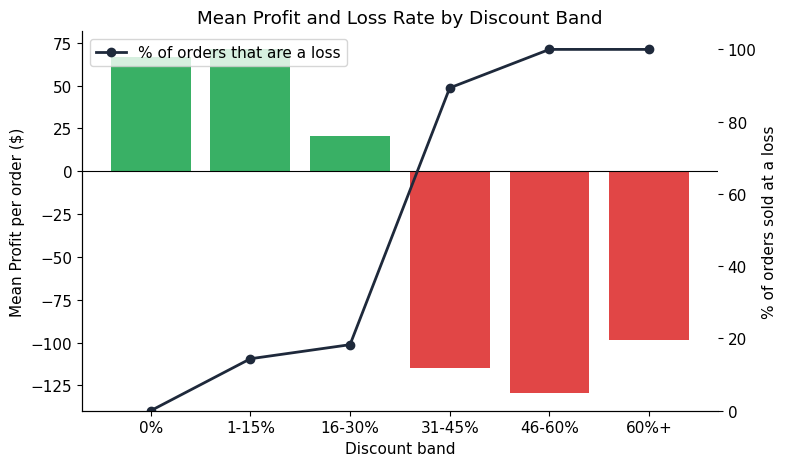

              mean_profit  loss_rate_%
DiscountBand                          
0%                  66.90          0.0
1-15%               71.56         14.4
16-30%              20.59         18.3
31-45%            -114.51         89.3
46-60%            -129.66        100.0
60%+               -98.35        100.0


In [11]:
bins = [-0.01, 0.0, 0.15, 0.3, 0.45, 0.6, 1.0]
labels = ["0%", "1-15%", "16-30%", "31-45%", "46-60%", "60%+"]
df["DiscountBand"] = pd.cut(df["Discount"], bins=bins, labels=labels)

grp = df.groupby("DiscountBand", observed=True)
mean_profit = grp["Profit"].mean()
loss_rate = grp.apply(lambda g: (g["Profit"] < 0).mean() * 100, include_groups=False)

fig, ax1 = plt.subplots(figsize=(8, 4.8))
colors = ["#16a34a" if v >= 0 else "#dc2626" for v in mean_profit]
ax1.bar(mean_profit.index, mean_profit.values, color=colors, alpha=0.85)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_ylabel("Mean Profit per order ($)"); ax1.set_xlabel("Discount band")
ax1.set_title("Mean Profit and Loss Rate by Discount Band")

ax2 = ax1.twinx()
ax2.plot(mean_profit.index, loss_rate.values, color="#1e293b", marker="o",
         linewidth=2, label="% of orders that are a loss")
ax2.set_ylabel("% of orders sold at a loss"); ax2.set_ylim(0, 105)
ax2.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"mean_profit": mean_profit.round(2), "loss_rate_%": loss_rate.round(1)}))

**This is the real finding.** Below ~30% discount, orders are almost always profitable
(0% loss rate at no discount, 18% loss rate at 16-30% discount). Above ~31%, the picture
flips hard: 89-100% of those orders are sold at a loss. It's not a gentle linear decline --
it's closer to a cliff around the 30% mark. That's exactly the kind of non-linear,
monotonic pattern Spearman is built to detect and Pearson isn't, which is why the two
numbers disagreed above.

**Assumption check:** Pearson's correlation test assumes a linear relationship -- which we
just showed is violated here. Reporting Pearson alone would understate the relationship;
Spearman plus the discount-band breakdown gives the honest picture.

**Practical significance:** statistically, both correlations are significant at p < .001,
which isn't surprising with n=9,994 -- at this sample size even small effects reach
significance. The band breakdown is what actually tells a manager something actionable:
discounting past ~30% is where losses become close to guaranteed, not a vague "more
discount, somewhat less profit" story.

## Distribution analysis (Profit)

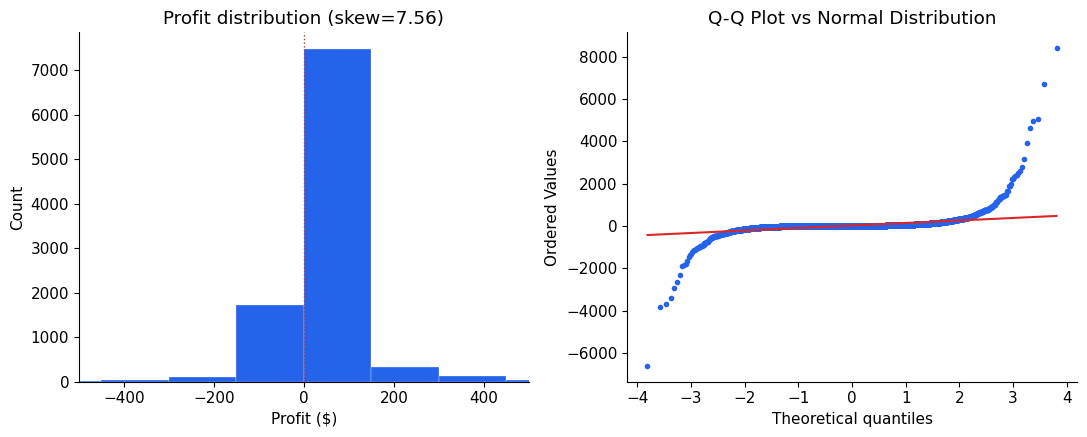

Skewness: 7.56  |  Excess kurtosis: 397.19
Shapiro-Wilk (n=3000 subsample): W=0.2981, p=4.04e-75 -> not normal


In [12]:
profit = df["Profit"]
skew = profit.skew()
kurt = profit.kurtosis()

# Shapiro-Wilk is unreliable above ~n=5000 in scipy, and at n=9994 it would
# reject normality trivially regardless -- so we test on a random subsample
# for validity, and lean on skew/kurtosis + the visuals as primary evidence.
rng = np.random.default_rng(42)
sample = rng.choice(profit.values, size=3000, replace=False)
shapiro_stat, shapiro_p = stats.shapiro(sample)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(profit, bins=100, color="#2563eb", edgecolor="white", linewidth=0.2)
axes[0].set_xlim(-500, 500)
axes[0].set_title(f"Profit distribution (skew={skew:.2f})")
axes[0].set_xlabel("Profit ($)"); axes[0].set_ylabel("Count")
axes[0].axvline(0, color="#dc2626", linestyle=":", linewidth=1)

stats.probplot(profit, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot vs Normal Distribution")
axes[1].get_lines()[0].set_markerfacecolor("#2563eb")
axes[1].get_lines()[0].set_markeredgecolor("#2563eb")
axes[1].get_lines()[0].set_markersize(3)
axes[1].get_lines()[1].set_color("#dc2626")
plt.tight_layout()
plt.show()

print(f"Skewness: {skew:.2f}  |  Excess kurtosis: {kurt:.2f}")
print(f"Shapiro-Wilk (n=3000 subsample): W={shapiro_stat:.4f}, p={shapiro_p:.2e} -> not normal")

**Shape:** heavily right-skewed with very heavy tails (skew of about 7.6, where a normal
distribution is 0) -- a sharp peak near small positive values with a long tail of large
profits and, on the other side, some severe losses. The Q-Q plot's S-curve away from the
red reference line confirms it isn't close to normal.

**On transforming it:** the standard fix for right skew is `np.log1p()`, but that assumes
non-negative values, and Profit includes real losses (negative values), so a plain log
transform can't be applied directly here. The methodologically correct option for a
variable that's skewed *and* signed is either a **signed-log transform**
(`np.sign(x) * np.log1p(np.abs(x))`, which preserves the loss/profit direction) or a
**Yeo-Johnson power transform** (`sklearn.preprocessing.PowerTransformer`), which is
designed to handle zero and negative values, unlike Box-Cox. We haven't applied it here
since it's not needed for the correlation test above (Pearson only needs *interval* data,
not normality, at this sample size -- the Central Limit Theorem covers us), but it would
matter if Profit were going into a linear regression.

## Report

A business report for a non-technical audience is in `report/Business_Report.pdf`. This notebook covers the code, all outputs, and the technical reasoning behind each decision above.
